# Paper figures (JEE print style)

Python replacement for the nine Stata figures in the paper (Stata license expired). Style and
data definitions live in `modules/figures.py`; deviations from the Stata code are documented in
each function's docstring.

JEE style sheet: black and white with arms distinguished by line pattern/weight, Times New Roman
bold 8-10 pt, at most 5 x 5 in, EPS/TIFF/JPEG at 600 dpi or more.

Outputs:
- `tex/plots/<name>.pdf` — vector PDF used by the LaTeX build
- `tex/plots/jee/<name>.eps`, `tex/plots/jee/<name>.tif` — submission files (TIFF is 600 dpi grayscale)

Encoding used throughout: **Incentive** = thick solid line / filled circle; **Control** = thin
dashed line / open circle; **Above median** = gray dotted line. 95% CIs are gray bands.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
from modules import figures as F
from modules.analysis_data import load_analysis_frame

DATA_RAW = "../data/raw"
DATA_GEN = "../data/generated"
PLOTS = "../tex/plots"

F.use_style()
%config InlineBackend.figure_format = "retina"

## Data

In [2]:
df = load_analysis_frame(DATA_GEN)
df = df.loc[df["arm"].notnull()]
weekly = pd.read_csv(f"{DATA_GEN}/id-year-weekoy-arm_level.csv", dtype={"id": str})
vids = F.video_watch_rates(DATA_RAW, df.loc[df["finalscore"].notnull()])
print(df.groupby("arm").size().rename(F.ARM_NAME))
print(f"{len(vids)} videos ({vids.incent.sum()} incentivized)")

arm
Above median    420
Control         215
Incentive       215
dtype: int64
73 videos (48 incentivized)


## effect of the incentive on videos watched (`combo_cdf`)

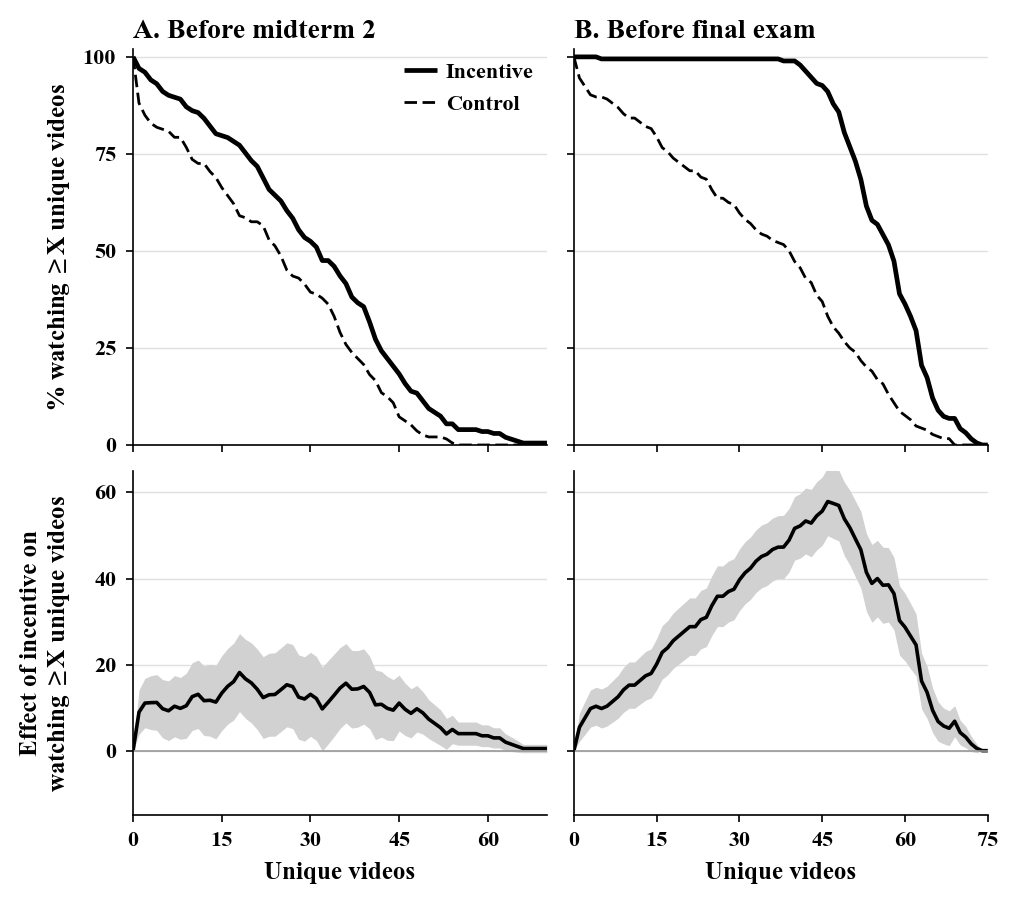

In [3]:
fig = F.fig_videos_survival(df)
F.save(fig, "combo_cdf", PLOTS)

## weekly video watching by arm (`tscombo`)

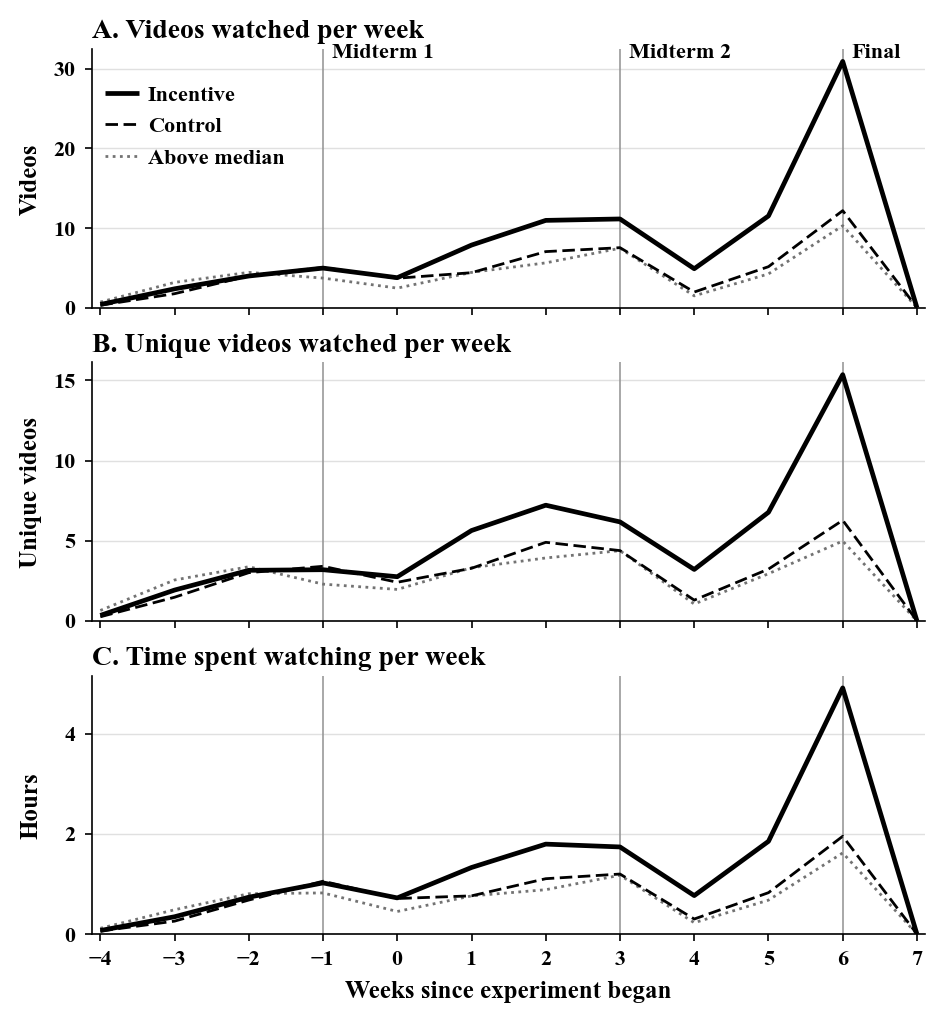

In [4]:
fig = F.fig_weekly(weekly)
F.save(fig, "tscombo", PLOTS)

## videos counted toward the incentive (`hist_v_incent`)

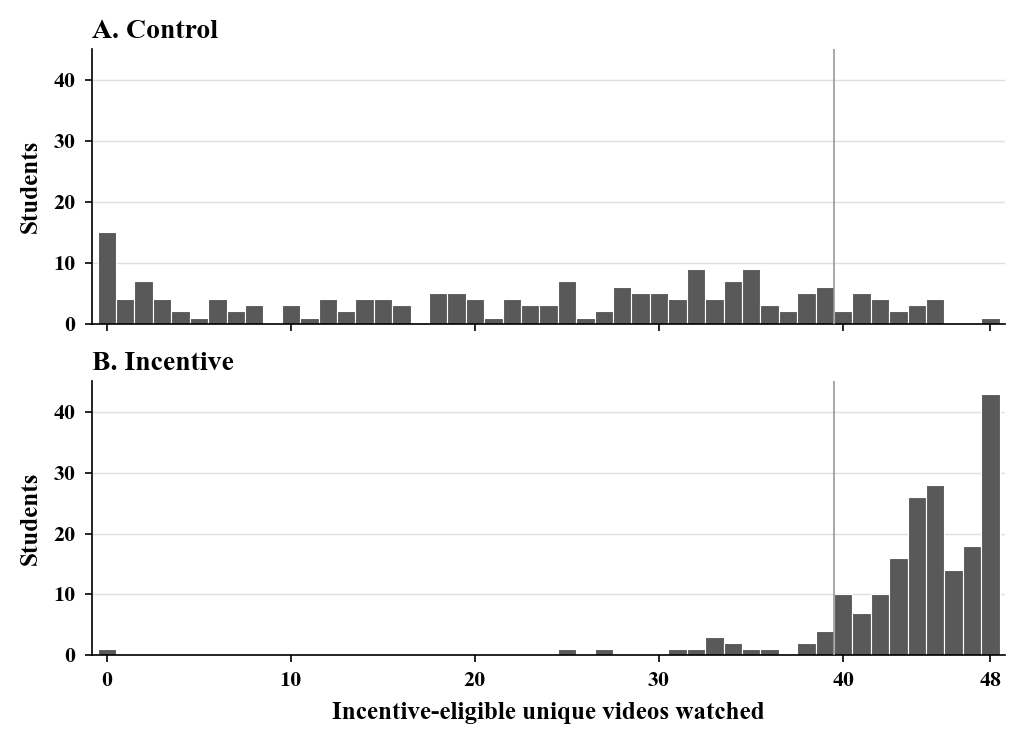

In [5]:
fig = F.fig_incentive_hist(df)
F.save(fig, "hist_v_incent", PLOTS)

## per-video watch rates (`bar_uviews`, `bar_uviews_week`, `bar_uviews_duration`)

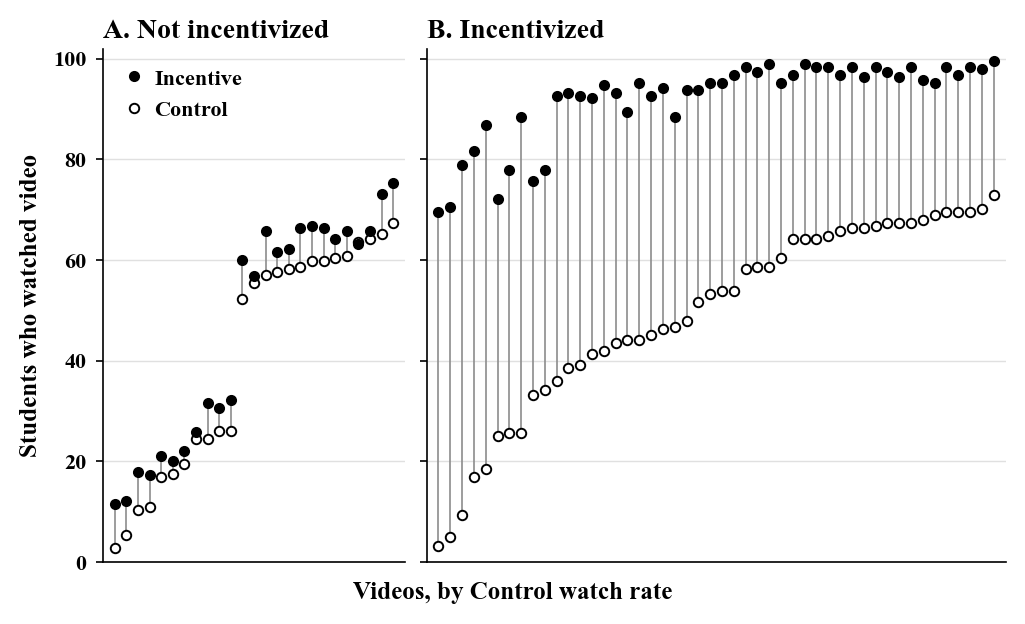

In [6]:
fig = F.fig_watch_rates_by_incentive(vids)
F.save(fig, "bar_uviews", PLOTS)

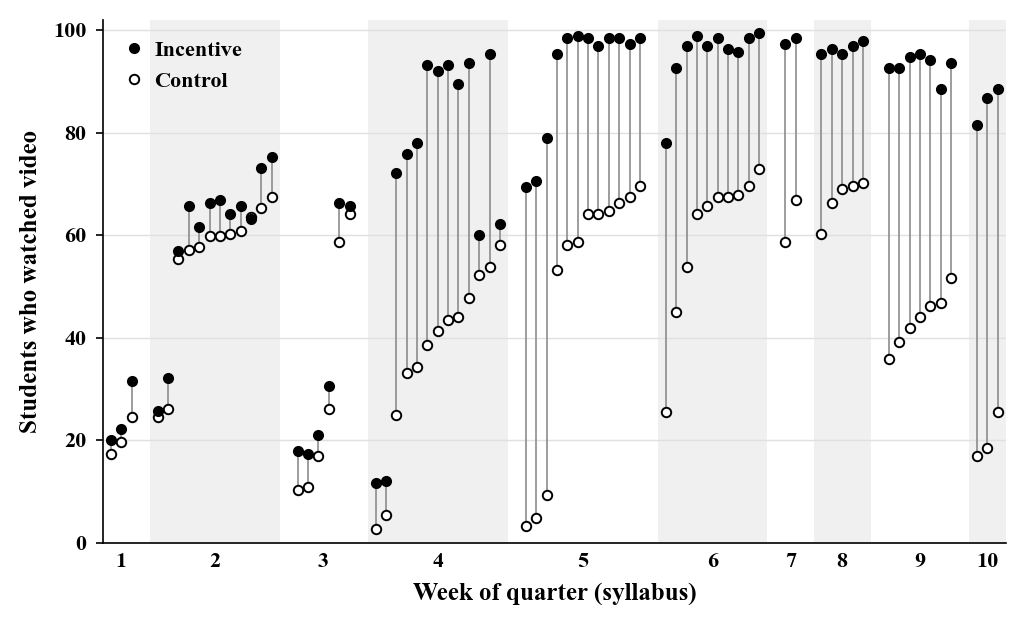

In [7]:
fig = F.fig_watch_rates_by_week(vids)
F.save(fig, "bar_uviews_week", PLOTS)

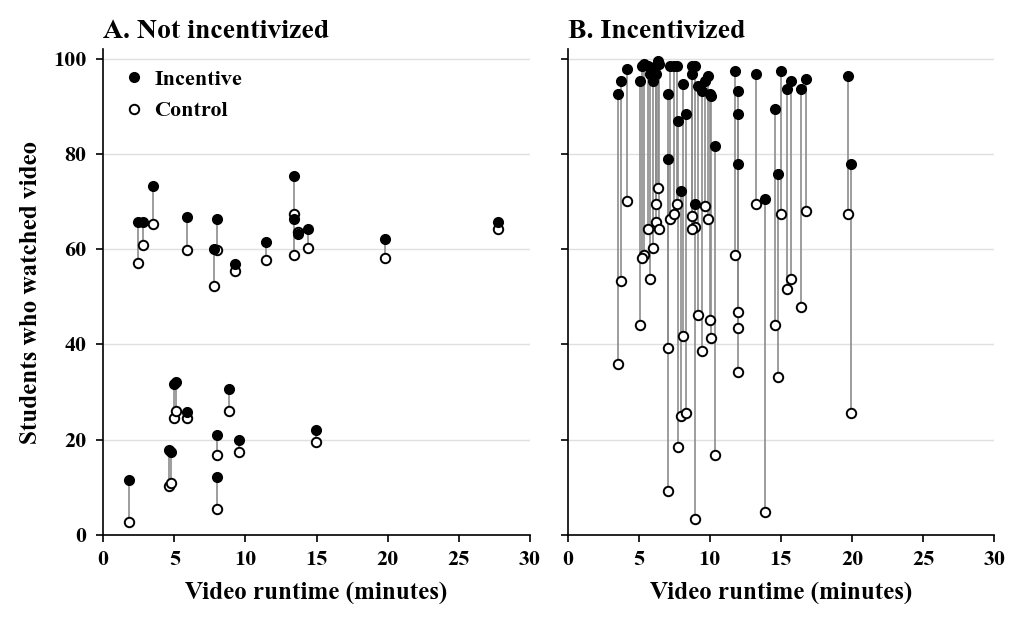

In [8]:
fig = F.fig_watch_rates_by_duration(vids)
F.save(fig, "bar_uviews_duration", PLOTS)

## effects along midterm 1 score (`lpolymid2`, `lpolyfinal`)

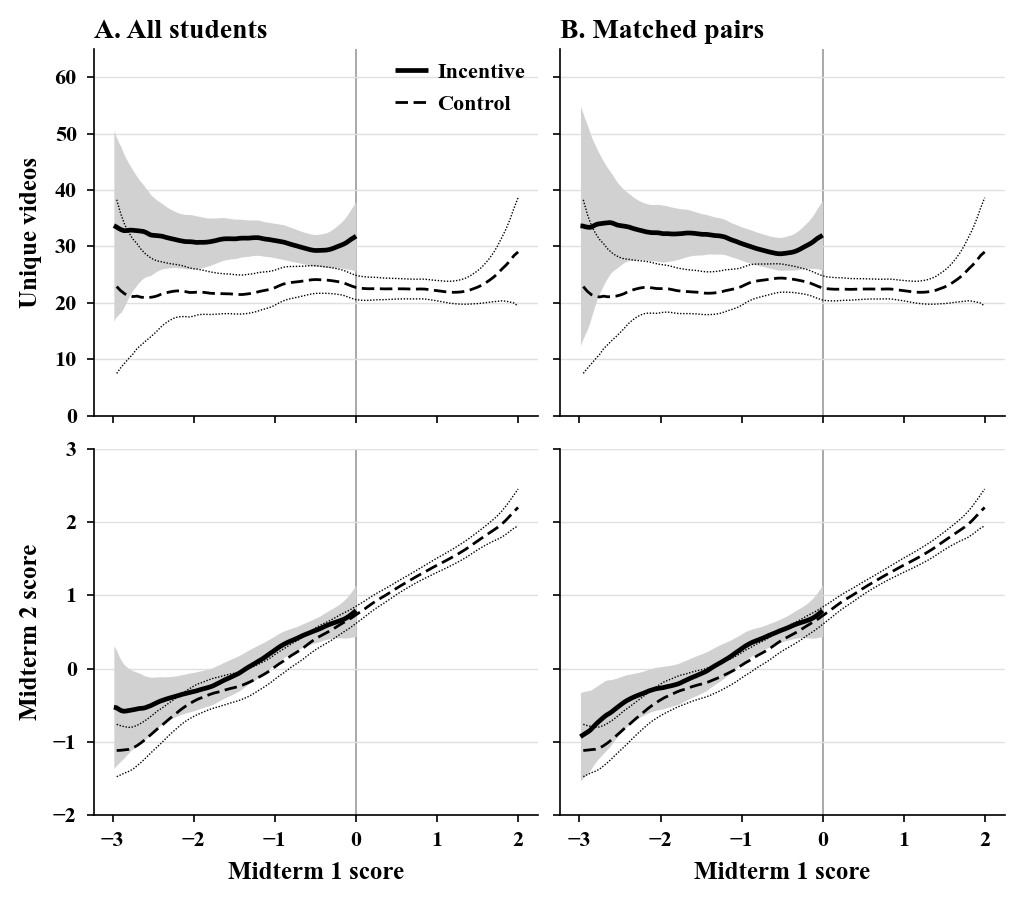

In [9]:
fig = F.fig_local_linear(df, "mid2")
F.save(fig, "lpolymid2", PLOTS)

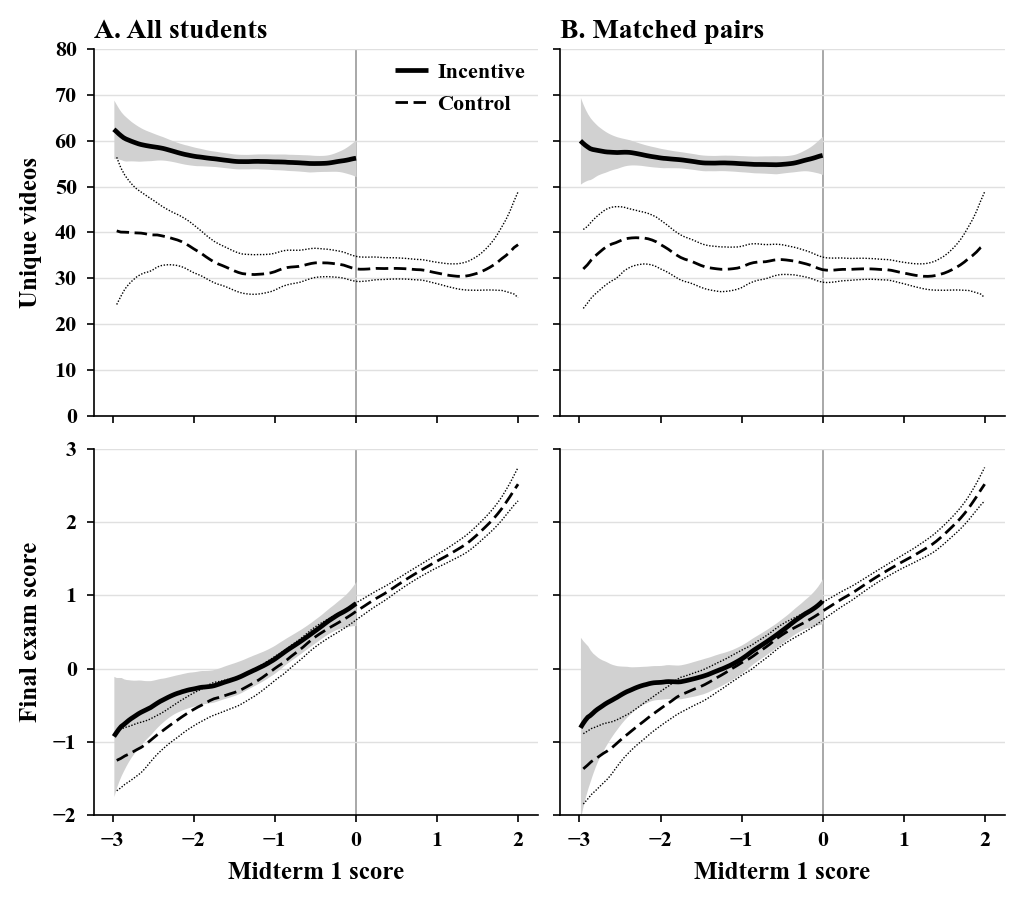

In [10]:
fig = F.fig_local_linear(df, "final")
F.save(fig, "lpolyfinal", PLOTS)

## most videos watched in one week (`hist_maxweek`)

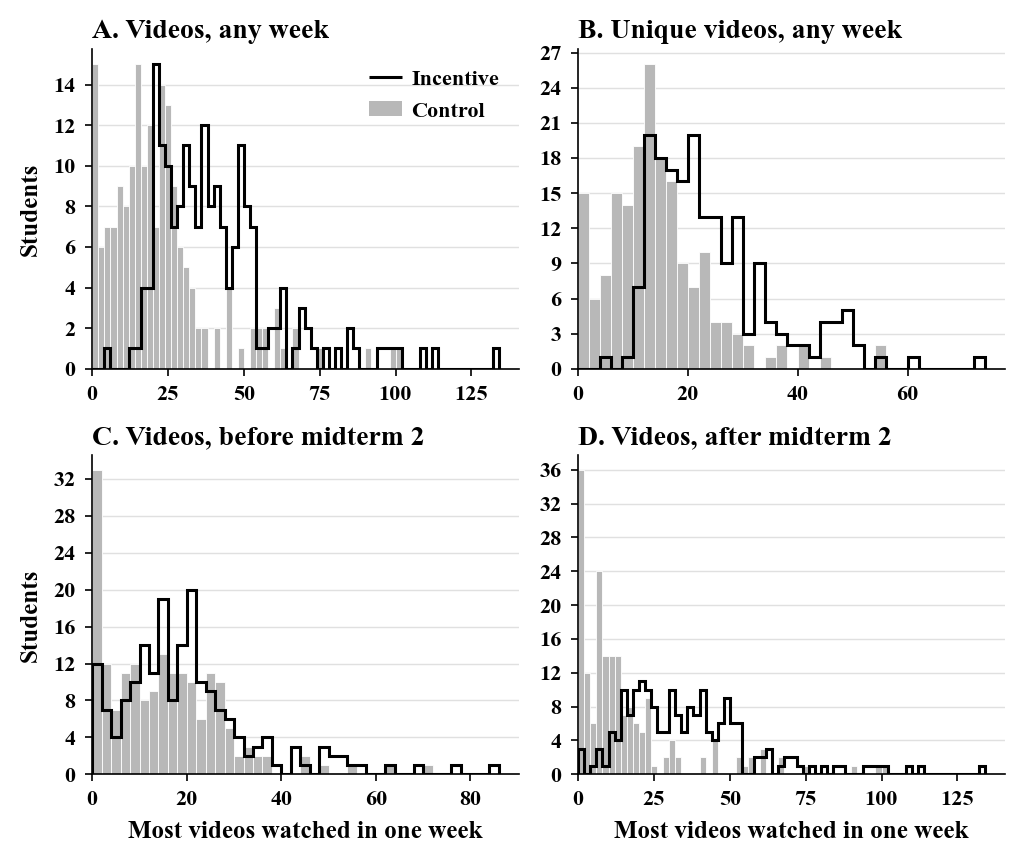

In [11]:
fig = F.fig_max_week(weekly)
F.save(fig, "hist_maxweek", PLOTS)